# 04 — Fit the pooled, segment and placebo choice models (cereal)

**Project:** Segment-Aware Demand Transference for Store-Level Assortment Decisions in Grocery Retail
**Pipeline notebook:** 04 (work-plan step 3 of 10) · **Data:** Dunnhumby Complete Journey, cereal, estimation weeks 1–75 only

This notebook fits the frozen specification from the work plan. **Weeks 76–102 (holdout) are not used here**; they are kept for the RQ1 comparison in Step 4.

| Model | Stage 1: which product (given a cereal purchase) | Stage 2: whether to buy cereal that week |
|---|---|---|
| Pooled | constant per alternative + shelf price, discount depth, display share (one set for everyone) | constant + category attractiveness + month dummies |
| Segment | constant per alternative + price, discount, display **per segment** + private label × segment | segment constants + attractiveness × segment + month dummies |
| Placebo | same as Segment, fitted on `segment_placebo` (shuffled labels) | same as Segment |

*Category attractiveness* is the stage-1 inclusive value: log Σ exp(utility) over the alternatives available that week.

**Identification.** Constants are only defined relative to each other, so the most-chosen alternative's constant is fixed at 0. The private-label main effect is absorbed by the alternative constants, so private label enters only as a difference from segment 1 (segments 2–4).

**Folder layout:** run from the project root, which holds `modelling_inputs_dunnhumby/` (from 02) and `step7_outputs/` (from 03).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy import stats
import matplotlib.pyplot as plt

INPUTS = Path("modelling_inputs_dunnhumby")
SEGS   = Path("step7_outputs")              # written by 03_Household_Segmentation.ipynb
OUT    = Path("outputs/choice_models"); OUT.mkdir(parents=True, exist_ok=True)
CAT, EST_END = "cereal", 75
pd.set_option("display.width", 140)

## 1. Load inputs

In [2]:
occ  = pd.read_parquet(INPUTS / f"choice_occasions_{CAT}.parquet")
aw   = pd.read_parquet(INPUTS / f"alt_week_{CAT}.parquet")
alts = pd.read_parquet(INPUTS / f"alternatives_{CAT}.parquet")
segs = pd.read_parquet(SEGS / "household_segments.parquet")[["household_key", "segment", "segment_placebo"]]

# Estimation window only; same households for every model (those with a segment)
est = occ[occ.week_no <= EST_END].merge(segs, on="household_key", how="inner")
assert est.week_no.max() <= EST_END, "holdout weeks leaked into estimation"
print(f"Estimation occasions: {len(est):,}  |  cereal purchases: {est.bought.sum():,}  |  households: {est.household_key.nunique():,}")

Estimation occasions: 83,632  |  cereal purchases: 15,904  |  households: 2,039


## 2. Build the alternative × week arrays

In [3]:
alt_ids = sorted(aw.alt_id.unique()); J = len(alt_ids); idx = {a: i for i, a in enumerate(alt_ids)}
aw["j"] = aw.alt_id.map(idx); NW = int(aw.week_no.max())

def grid(col):
    g = np.zeros((J, NW + 1)); g[aw.j, aw.week_no] = aw[col].fillna(0).values; return g
AVAIL = np.zeros((J, NW + 1), bool); AVAIL[aw.j, aw.week_no] = aw.available.values
PRICE, DISC, DISP = grid("price"), grid("disc_depth"), grid("display_share")
PL = alts.set_index("alt_id").loc[alt_ids, "is_private"].values.astype(float)

est["j"] = est.chosen.map(idx).fillna(-1).astype(int)          # -1 = outside option
REF = idx[alts.sort_values("est_choices", ascending=False).alt_id.iloc[0]]   # reference alternative (constant = 0)
asc_cols = [i for i in range(J) if i != REF]
print(f"Alternatives: {J}  |  reference alternative: {alt_ids[REF]}  |  private-label alternatives: {int(PL.sum())}")

Alternatives: 227  |  reference alternative: 1071342  |  private-label alternatives: 60


## 3. Stage 1 — which product, given a cereal purchase

Every household in the same week and segment faces the same choice set and the same utilities, so the likelihood is computed per (week, segment) group with choice counts. This is exact, not an approximation, and makes the fit fast.

In [4]:
NSEG, XNAMES = 4, ["price", "discount_depth", "display_share"]

def design(A, w, s, segmented):
    """Rows = available alternatives A in week w for segment s; columns = parameters."""
    asc = np.zeros((len(A), J - 1)); pos = {c: k for k, c in enumerate(asc_cols)}
    for r, a in enumerate(A):
        if a != REF: asc[r, pos[a]] = 1
    X = np.column_stack([PRICE[A, w], DISC[A, w], DISP[A, w]])
    if not segmented:
        return np.hstack([asc, X])
    B = np.zeros((len(A), NSEG * 3)); B[:, 3 * s:3 * s + 3] = X
    P = np.zeros((len(A), NSEG - 1))
    if s > 0: P[:, s - 1] = PL[A]
    return np.hstack([asc, B, P])

def stage1_groups(segcol, segmented):
    buys = est[est.bought == 1]
    groups = []
    for (w, s), g in buys.groupby(["week_no", segcol]):
        s = int(s) - 1 if segmented else 0
        A = np.where(AVAIL[:, w])[0]; pos = np.full(J, -1); pos[A] = np.arange(len(A))
        assert (pos[g.j.values] >= 0).all(), "a chosen alternative was not available"
        groups.append(dict(Z=design(A, w, s, segmented), n=np.bincount(pos[g.j.values], minlength=len(A)).astype(float)))
    return groups

def loglik(theta, groups):
    L, G = 0.0, np.zeros_like(theta)
    for g in groups:
        V = g["Z"] @ theta; m = V.max(); lse = m + np.log(np.exp(V - m).sum()); P = np.exp(V - lse); N = g["n"].sum()
        L += g["n"] @ V - N * lse
        G += g["Z"].T @ (g["n"] - N * P)
    return -L, -G

def hessian(theta, groups):
    H = np.zeros((len(theta), len(theta)))
    for g in groups:
        V = g["Z"] @ theta; P = np.exp(V - V.max()); P /= P.sum(); N = g["n"].sum(); Zb = P @ g["Z"]
        H += N * ((g["Z"] * P[:, None]).T @ g["Z"] - np.outer(Zb, Zb))
    return H        # information matrix (negative Hessian of the log-likelihood)

def fit_stage1(segcol, segmented):
    groups = stage1_groups(segcol, segmented)
    k = groups[0]["Z"].shape[1]
    r = minimize(loglik, np.zeros(k), args=(groups,), jac=True, method="L-BFGS-B", options=dict(maxiter=5000, gtol=1e-8))
    theta = r.x
    for _ in range(5):                                    # Newton polish for an exact optimum
        I = hessian(theta, groups); g = -loglik(theta, groups)[1]; theta = theta + np.linalg.solve(I, g)
    I = hessian(theta, groups); nll, grad = loglik(theta, groups)
    cov = np.linalg.inv(I)
    return dict(theta=theta, se=np.sqrt(np.diag(cov)), ll=-nll, k=k, n=int(sum(g["n"].sum() for g in groups)),
                grad_norm=float(np.abs(grad).max()), min_eig=float(np.linalg.eigvalsh(I).min()), groups=groups)

In [5]:
SPEC = {"pooled": ("segment", False), "segment": ("segment", True), "placebo": ("segment_placebo", True)}
s1 = {name: fit_stage1(col, segm) for name, (col, segm) in SPEC.items()}
for name, f in s1.items():
    print(f"{name:8s} log-lik {f['ll']:12.1f} | params {f['k']:3d} | purchases {f['n']:,} | max |gradient| {f['grad_norm']:.1e} | min eigenvalue {f['min_eig']:.2e}")

pooled   log-lik     -79551.0 | params 229 | purchases 15,904 | max |gradient| 3.6e-13 | min eigenvalue 7.72e-01
segment  log-lik     -78648.5 | params 241 | purchases 15,904 | max |gradient| 6.0e-13 | min eigenvalue 7.49e-01
placebo  log-lik     -79544.0 | params 241 | purchases 15,904 | max |gradient| 2.0e-12 | min eigenvalue 7.54e-01


### Stage 1 coefficients (alternative constants saved separately)

In [6]:
def term_names(segmented):
    if not segmented: return XNAMES
    return [f"{x} | seg {s+1}" for s in range(NSEG) for x in XNAMES] + [f"private_label | seg {s} (vs seg 1)" for s in range(2, NSEG + 1)]

rows, asc_tables = [], {}
for name, (col, segm) in SPEC.items():
    f = s1[name]; b, se = f["theta"][J - 1:], f["se"][J - 1:]
    for t, est_, s_ in zip(term_names(segm), b, se):
        z = est_ / s_; rows.append(dict(model=name, term=t, estimate=est_, std_error=s_, z=z, p_value=2 * stats.norm.sf(abs(z))))
    asc = np.insert(f["theta"][:J - 1], REF, 0.0); asc_se = np.insert(f["se"][:J - 1], REF, 0.0)
    asc_tables[name] = pd.DataFrame(dict(alt_id=alt_ids, constant=asc, std_error=asc_se, reference=[i == REF for i in range(J)]))
coef1 = pd.DataFrame(rows)
coef1.round(4)

,model,term,estimate,std_error,z,p_value
0,pooled,price,-0.1286,0.0467,-2.7545,0.0059
1,pooled,discount_depth,2.6926,0.0771,34.9089,0.0000
2,pooled,display_share,0.6382,0.0381,16.7508,0.0000
3,segment,price | seg 1,0.0418,0.0481,0.8697,0.3845
4,segment,discount_depth | seg 1,1.2624,0.1133,11.1466,0.0000
5,segment,display_share | seg 1,0.3252,0.0647,5.0267,0.0000
6,segment,price | seg 2,-0.3667,0.0509,-7.2043,0.0000
7,segment,discount_depth | seg 2,4.0340,0.1259,32.0303,0.0000
8,segment,display_share | seg 2,0.8459,0.0625,13.5392,0.0000
9,segment,price | seg 3,-0.3417,0.0598,-5.7116,0.0000


## 4. Stage 2 — whether to buy cereal that week

Category attractiveness (the inclusive value) is computed for every week and segment from the stage-1 estimates. A logistic regression then explains cereal purchase across all estimation occasions, including weeks with no cereal purchase.

Note: stage-2 standard errors treat attractiveness as known, so they are slightly too small (a standard two-step caveat to state in the thesis).

In [7]:
def attractiveness(name):
    col, segm = SPEC[name]; th = s1[name]["theta"]; iv = np.full((NW + 1, NSEG), np.nan)
    for w in range(1, NW + 1):
        A = np.where(AVAIL[:, w])[0]
        for s in range(NSEG if segm else 1):
            V = design(A, w, s, segm) @ th; m = V.max(); iv[w, s] = m + np.log(np.exp(V - m).sum())
        if not segm: iv[w, :] = iv[w, 0]
    return iv

def month(w): return ((np.asarray(w) - 1) // 4.35).astype(int) % 12

def stage2_frame(name):
    col, segm = SPEC[name]; iv = attractiveness(name)
    s = est[col].values.astype(int) - 1; w = est.week_no.values
    X = pd.DataFrame(index=est.index)
    if segm:
        for k in range(NSEG):
            X[f"const | seg {k+1}"] = (s == k).astype(float)
            X[f"attractiveness | seg {k+1}"] = (s == k) * iv[w, k]
    else:
        X["const"] = 1.0; X["attractiveness"] = iv[w, 0]
    mo = month(w)
    for m in range(1, 12): X[f"month_{m}"] = (mo == m).astype(float)
    return X, iv

s2, rows = {}, []
for name in SPEC:
    X, iv = stage2_frame(name)
    res = sm.Logit(est.bought.values, X).fit(disp=0, maxiter=200)
    s2[name] = dict(res=res, iv=iv)
    for t in X.columns:
        rows.append(dict(model=name, term=t, estimate=res.params[t], std_error=res.bse[t], z=res.tvalues[t], p_value=res.pvalues[t]))
coef2 = pd.DataFrame(rows)
coef2[~coef2.term.str.startswith("month")].round(4)

,model,term,estimate,std_error,z,p_value
0,pooled,const,-2.4961,0.3233,-7.7197,0.0000
1,pooled,attractiveness,0.2507,0.0767,3.2676,0.0011
13,segment,const | seg 1,-2.1594,0.6400,-3.3743,0.0007
14,segment,attractiveness | seg 1,0.1806,0.1412,1.2786,0.2010
15,segment,const | seg 2,-2.2867,0.3835,-5.9620,0.0000
16,segment,attractiveness | seg 2,0.2278,0.1040,2.1899,0.0285
17,segment,const | seg 3,-2.1990,0.7251,-3.0328,0.0024
18,segment,attractiveness | seg 3,0.0749,0.1786,0.4194,0.6749
19,segment,const | seg 4,-3.6863,0.6767,-5.4476,0.0000
20,segment,attractiveness | seg 4,0.5791,0.1582,3.6601,0.0003


## 5. Checks required by the frozen specification

- **Attractiveness slope in (0, 1]:** the two-stage model is only consistent with utility maximisation in this range. Outside it, the model would predict impossible substitution (this is why the single-stage version was rejected).
- **Price sign:** reported as estimated; it is **not** constrained.
- **In-sample likelihood-ratio tests (estimation weeks only):** does the segment model fit significantly better than the pooled model, and does the placebo? The out-of-sample test is Step 4.

In [8]:
chk = []
for name in SPEC:
    p = s2[name]["res"].params
    for t in [t for t in p.index if t.startswith("attractiveness")]:
        chk.append(dict(model=name, term=t, slope=p[t], in_valid_range=0 < p[t] <= 1))
print(pd.DataFrame(chk).round(3).to_string(index=False))

price = coef1[coef1.term.str.startswith("price")][["model", "term", "estimate", "std_error", "p_value"]]
print("\nPrice coefficients (not constrained):"); print(price.round(4).to_string(index=False))

def lr(a, b):
    stat = 2 * (s1[b]["ll"] - s1[a]["ll"]); df = s1[b]["k"] - s1[a]["k"]
    return dict(comparison=f"{b} vs {a} (stage 1)", lr_stat=stat, df=df, p_value=stats.chi2.sf(stat, df))
lrt = pd.DataFrame([lr("pooled", "segment"), lr("pooled", "placebo")])
print("\nIn-sample likelihood-ratio tests:"); print(lrt.round(4).to_string(index=False))

  model                   term  slope  in_valid_range
 pooled         attractiveness  0.251            True
segment attractiveness | seg 1  0.181            True
segment attractiveness | seg 2  0.228            True
segment attractiveness | seg 3  0.075            True
segment attractiveness | seg 4  0.579            True
placebo attractiveness | seg 1  0.232            True
placebo attractiveness | seg 2  0.363            True
placebo attractiveness | seg 3  0.125            True
placebo attractiveness | seg 4  0.194            True

Price coefficients (not constrained):
  model          term  estimate  std_error  p_value
 pooled         price   -0.1286     0.0467   0.0059
segment price | seg 1    0.0418     0.0481   0.3845
segment price | seg 2   -0.3667     0.0509   0.0000
segment price | seg 3   -0.3417     0.0598   0.0000
segment price | seg 4   -0.1759     0.0520   0.0007
placebo price | seg 1   -0.1078     0.0488   0.0272
placebo price | seg 2   -0.1312     0.0501   0.0088
place

## 6. Fit summary (estimation weeks only)

In [9]:
summ = []
for name in SPEC:
    f, r = s1[name], s2[name]["res"]; n2 = int(r.nobs)
    summ.append(dict(model=name, stage1_loglik=f["ll"], stage1_params=f["k"], stage1_purchases=f["n"],
                     stage1_AIC=2 * f["k"] - 2 * f["ll"], stage1_BIC=np.log(f["n"]) * f["k"] - 2 * f["ll"],
                     stage2_loglik=r.llf, stage2_params=len(r.params), stage2_occasions=n2,
                     stage2_AIC=r.aic, stage2_BIC=r.bic))
summary = pd.DataFrame(summ)
summary.round(1)

,model,stage1_loglik,stage1_params,stage1_purchases,stage1_AIC,stage1_BIC,stage2_loglik,stage2_params,stage2_occasions,stage2_AIC,stage2_BIC
0,pooled,-79551.0,229,15904,159559.9,161317.4,-40666.4,13,83632,81358.7,81480.0
1,segment,-78648.5,241,15904,157779.0,159628.6,-40387.6,19,83632,80813.3,80990.6
2,placebo,-79544.0,241,15904,159569.9,161419.5,-40657.5,19,83632,81353.0,81530.3


## 7. Figure — stage-1 effects by segment (95% intervals); grey line = pooled estimate

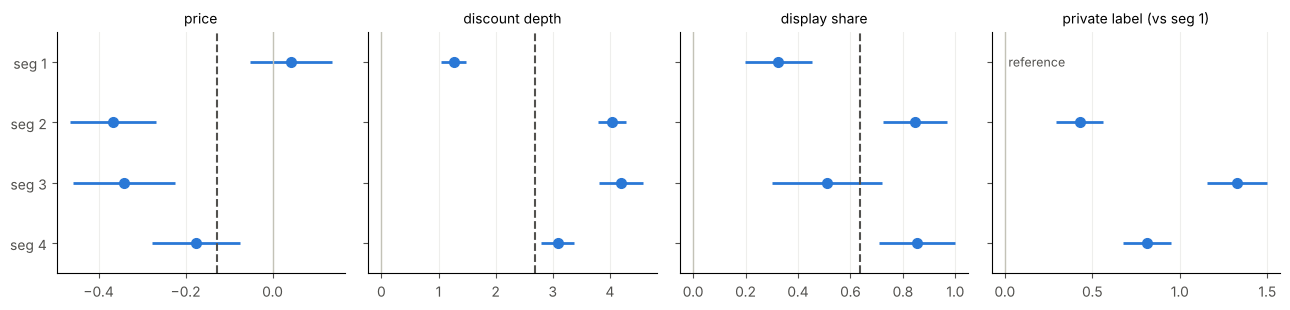

In [10]:
seg_c = coef1[coef1.model == "segment"].copy()
pool  = coef1[coef1.model == "pooled"].set_index("term").estimate
terms = XNAMES + ["private_label"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, t in zip(axes, terms):
    d = seg_c[seg_c.term.str.startswith(t)]
    y = np.array([int(x.split("seg ")[1].split()[0]) - 1 for x in d.term])   # fixed row per segment
    ax.errorbar(d.estimate, y, xerr=1.96 * d.std_error, fmt="o", color="#2a78d6", ms=7, capsize=0, elinewidth=2)
    ax.axvline(0, color="#c3c2b7", lw=1)
    if t in pool.index: ax.axvline(pool[t], color="#52514e", lw=1.5, ls="--")
    if t == "private_label": ax.text(0.02, 0, "reference", color="#52514e", fontsize=9, va="center")
    ax.set_title(t.replace("_", " ") + (" (vs seg 1)" if t == "private_label" else ""), fontsize=10)
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    ax.tick_params(colors="#52514e"); ax.grid(axis="x", color="#eeeeec")
axes[0].set_yticks(range(NSEG), [f"seg {k+1}" for k in range(NSEG)]); axes[0].set_ylim(NSEG - 0.5, -0.5)
fig.tight_layout()
fig.savefig(OUT / "stage1_effects_by_segment.png", dpi=150); plt.show()

## 8. Save outputs for Steps 4–6

In [11]:
coef1.to_csv(OUT / "stage1_coefficients.csv", index=False)
coef2.to_csv(OUT / "stage2_coefficients.csv", index=False)
summary.to_csv(OUT / "fit_summary.csv", index=False)
lrt.to_csv(OUT / "lr_tests_in_sample.csv", index=False)
for name, t in asc_tables.items(): t.to_csv(OUT / f"stage1_constants_{name}.csv", index=False)

params = {"category": CAT, "estimation_weeks": [1, EST_END], "alt_ids": alt_ids, "reference_alt": alt_ids[REF],
          "stage1_x": XNAMES, "month_rule": "((week-1)//4.35) % 12, month 0 = reference", "models": {}}
for name, (col, segm) in SPEC.items():
    params["models"][name] = {"segment_column": col, "segmented": segm,
                              "stage1_theta": s1[name]["theta"].tolist(), "stage1_terms": term_names(segm),
                              "stage2_params": s2[name]["res"].params.to_dict()}
json.dump(params, open(OUT / "model_params.json", "w"), indent=1)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  fit_summary.csv
  lr_tests_in_sample.csv
  model_params.json
  stage1_coefficients.csv
  stage1_constants_placebo.csv
  stage1_constants_pooled.csv
  stage1_constants_segment.csv
  stage1_effects_by_segment.png
  stage2_coefficients.csv


## 9. What to carry into Step 4

- `model_params.json` holds everything needed to predict on the holdout weeks (Step 4) and to simulate removals (Step 5) without refitting.
- Report the coefficient tables and the figure as estimated, including any wrong-signed price effect.
- Do **not** change the specification after looking at the Step 4 results.